In [1]:
import os
import time
import json
import random
import numpy as np
import matplotlib.pyplot as plt
import csv
from pathlib import Path
from collections import Counter

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

SEED = 42
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

DATA_ROOT = Path('data')
OUT = Path('artifacts')
OUT.mkdir(exist_ok=True)

BATCH_SIZE = 32
MAX_EPOCHS = 18
PATIENCE = 4
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [3]:
source_train = datasets.OxfordIIITPet(root=DATA_ROOT, split='trainval', download=True)
source_test = datasets.OxfordIIITPet(root=DATA_ROOT, split='test', download=True)

selected = [0, 5, 6, 7, 9, 1, 2, 3, 4, 8]
CLASS_NAMES = [source_train.classes[k] for k in selected]
label_map = {old: new for new, old in enumerate(selected)}

records = []
for i, y in enumerate(source_train._labels):
    if y in label_map:
        records.append((0, i, label_map[y]))

for i, y in enumerate(source_test._labels):
    if y in label_map:
        records.append((1, i, label_map[y]))

labels = np.array([r[2] for r in records])
indices = np.arange(len(records))

train_idx, temp_idx = train_test_split(indices, test_size=0.30, stratify=labels, random_state=SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, stratify=labels[temp_idx], random_state=SEED)

splits = {
    'train': sorted(map(int, train_idx)),
    'val': sorted(map(int, val_idx)),
    'test': sorted(map(int, test_idx))
}

In [4]:
WEIGHTS = models.ResNet18_Weights.IMAGENET1K_V1
mean = WEIGHTS.transforms().mean
std = WEIGHTS.transforms().std

plain = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

augmented = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

class PetSubset(Dataset):
    def __init__(self, idx_list, transform):
        self.idx_list = list(idx_list)
        self.transform = transform

    def __len__(self):
        return len(self.idx_list)

    def __getitem__(self, k):
        src, row, y = records[self.idx_list[k]]
        img, _ = (source_train if src == 0 else source_test)[row]
        return self.transform(img), y

def make_loaders(train_transform):
    gen = torch.Generator().manual_seed(SEED)
    return {
        'train': DataLoader(PetSubset(splits['train'], train_transform), batch_size=BATCH_SIZE, shuffle=True, generator=gen),
        'val': DataLoader(PetSubset(splits['val'], plain), batch_size=BATCH_SIZE, shuffle=False),
        'test': DataLoader(PetSubset(splits['test'], plain), batch_size=BATCH_SIZE, shuffle=False)
    }

In [7]:
def set_training_mode(model, mode, architecture):
    model.train()
    if mode == 'extract':
        if architecture == 'resnet18':
            for name, child in model.named_children():
                if name != 'fc':
                    child.eval()
        else:
            model.features.eval()
    elif mode == 'finetune':
        if architecture == 'resnet18':
            for name, child in model.named_children():
                if name not in ('fc', 'layer4'):
                    child.eval()
        else:
            model.features.eval()
            model.features[-1].train()

def run_epoch(model, loader, criterion, optimizer=None, mode=None, architecture=None):
    if optimizer is None:
        model.eval()
    else:
        set_training_mode(model, mode, architecture)
        
    total_loss, total_correct, total_samples = 0.0, 0, 0
    all_preds, all_truths = [], []
    
    for images, targets in loader:
        images, targets = images.to(DEVICE), targets.to(DEVICE)
        
        if optimizer is not None:
            optimizer.zero_grad()
            
        with torch.set_grad_enabled(optimizer is not None):
            logits = model(images)
            loss = criterion(logits, targets)
            if optimizer is not None:
                loss.backward()
                optimizer.step()
                
        preds = logits.argmax(dim=1)
        batch_n = targets.size(0)
        total_samples += batch_n
        total_loss += loss.item() * batch_n
        total_correct += (preds == targets).sum().item()
        
        all_preds.extend(preds.cpu().tolist())
        all_truths.extend(targets.cpu().tolist())
        
    avg_loss = total_loss / total_samples
    acc = total_correct / total_samples
    macro_f1 = f1_score(all_truths, all_preds, average='macro', zero_division=0)
    return {'loss': avg_loss, 'accuracy': acc, 'macro_f1': macro_f1}

def train_experiment(name, mode, augmentation, model, optimizer, loaders, architecture='resnet18'):
    
    params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total_params = sum(p.numel() for p in model.parameters())
    rates = [group['lr'] for group in optimizer.param_groups]
    criterion = nn.CrossEntropyLoss()
    
    best_loss = float('inf')
    best_epoch = 0
    best_weights = None
    stale = 0
    history = []
    
    start_time = time.time()
    for epoch in range(1, MAX_EPOCHS + 1):
        train_res = run_epoch(model, loaders['train'], criterion, optimizer, mode, architecture)
        val_res = run_epoch(model, loaders['val'], criterion)
        
        history.append({
            'experiment': name, 'epoch': epoch,
            'train_loss': train_res['loss'], 'train_accuracy': train_res['accuracy'], 'train_macro_f1': train_res['macro_f1'],
            'val_loss': val_res['loss'], 'val_accuracy': val_res['accuracy'], 'val_macro_f1': val_res['macro_f1']
        })
        print(f"{name} {epoch:02d} | train {train_res['loss']:.4f}/{train_res['accuracy']:.3f} | val {val_res['loss']:.4f}/{val_res['accuracy']:.3f}")
        
        if val_res['loss'] < best_loss - 1e-4:
            best_loss = val_res['loss']
            best_epoch = epoch
            stale = 0
            best_weights = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
            if stale >= PATIENCE:
                print(f"Early stopping tercapai pada epoch {epoch}")
                break
                
    elapsed = time.time() - start_time
    model.load_state_dict(best_weights)
    val_best = run_epoch(model, loaders['val'], criterion)
    
    result = {
        'experiment': name, 'mode': mode, 'augmentation': augmentation, 'architecture': architecture,
        'trainable_parameters': params, 'total_parameters': total_params, 'learning_rates': rates,
        'epochs_ran': len(history), 'best_epoch': best_epoch, 'duration_seconds': elapsed,
        'train_accuracy': history[best_epoch - 1]['train_accuracy'],
        'validation_accuracy': val_best['accuracy'], 'validation_loss': val_best['loss']
    }
    
    torch.save(best_weights, OUT / f'{name}.pt')
    (OUT / f'{name}_result.json').write_text(json.dumps(result, indent=2), encoding='utf-8')
    return result, history

In [8]:
# Baseline
RESULTS, HISTORIES = {}, {}

name, mode, aug = 'B1_scratch', 'scratch', False
seed_everything(SEED)
loaders = make_loaders(augmented if aug else plain)

model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 10)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-2)
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())

model = model.to(DEVICE)
RESULTS[name], HISTORIES[name] = train_experiment(name, mode, aug, model, optimizer, loaders)
del model, optimizer, loaders


B1_scratch 01 | train 2.0489/0.273 | val 1.9643/0.350
B1_scratch 02 | train 1.6066/0.460 | val 1.8320/0.394
B1_scratch 03 | train 1.2669/0.583 | val 1.8729/0.391
B1_scratch 04 | train 0.8002/0.795 | val 2.0681/0.364
B1_scratch 05 | train 0.3733/0.939 | val 2.0471/0.431
B1_scratch 06 | train 0.1777/0.977 | val 2.2331/0.364
Early stopping tercapai pada epoch 6


In [9]:
# Feature Extraction
name, mode, aug = 'B2_extract', 'extract', False
seed_everything(SEED)
loaders = make_loaders(augmented if aug else plain)

weights = models.ResNet18_Weights.IMAGENET1K_V1
model = models.resnet18(weights=weights)

for param in model.parameters():
    param.requires_grad = False

num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 10)

optimizer = torch.optim.AdamW(model.fc.parameters(), lr=1e-3, weight_decay=1e-2)
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print(f"Trainable Parameters: {trainable_params:,} / {total_params:,}")
model = model.to(DEVICE)
RESULTS[name], HISTORIES[name] = train_experiment(name, mode, aug, model, optimizer, loaders)
del model, optimizer, loaders


Trainable Parameters: 5,130 / 11,181,642
B2_extract 01 | train 1.3376/0.604 | val 0.6691/0.882
B2_extract 02 | train 0.5140/0.905 | val 0.4002/0.912
B2_extract 03 | train 0.3399/0.929 | val 0.3044/0.949
B2_extract 04 | train 0.2671/0.942 | val 0.2725/0.949
B2_extract 05 | train 0.2222/0.948 | val 0.2386/0.956
B2_extract 06 | train 0.1964/0.960 | val 0.2294/0.956
B2_extract 07 | train 0.1721/0.966 | val 0.2260/0.949
B2_extract 08 | train 0.1572/0.970 | val 0.2212/0.943
B2_extract 09 | train 0.1432/0.971 | val 0.2269/0.926
B2_extract 10 | train 0.1311/0.976 | val 0.2142/0.939
B2_extract 11 | train 0.1215/0.970 | val 0.2046/0.946
B2_extract 12 | train 0.1106/0.981 | val 0.2012/0.949
B2_extract 13 | train 0.1002/0.984 | val 0.2026/0.946
B2_extract 14 | train 0.0942/0.985 | val 0.2035/0.936
B2_extract 15 | train 0.0889/0.986 | val 0.1996/0.949
B2_extract 16 | train 0.0800/0.989 | val 0.2084/0.933
B2_extract 17 | train 0.0760/0.988 | val 0.2041/0.939
B2_extract 18 | train 0.0718/0.992 | val 

In [10]:
# Fine tuning
name, mode, aug = 'B3_finetune', 'finetune', False
seed_everything(SEED)
loaders = make_loaders(augmented if aug else plain)
# B3 & B4: Progressive Fine-Tuning
weights = models.ResNet18_Weights.IMAGENET1K_V1
model = models.resnet18(weights=weights)

for param in model.parameters():
    param.requires_grad = False

num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 10)

for param in model.layer4.parameters():
    param.requires_grad = True

optimizer = torch.optim.AdamW([
    {"params": model.layer4.parameters(), "lr": 1e-4},
    {"params": model.fc.parameters(), "lr": 1e-3},
], weight_decay=1e-2)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print(f"Trainable Parameters: {trainable_params:,} / {total_params:,}")
model = model.to(DEVICE)
RESULTS[name], HISTORIES[name] = train_experiment(name, mode, aug, model, optimizer, loaders)
del model, optimizer, loaders


Trainable Parameters: 8,398,858 / 11,181,642
B3_finetune 01 | train 0.7472/0.772 | val 0.2162/0.936
B3_finetune 02 | train 0.1179/0.976 | val 0.1857/0.953
B3_finetune 03 | train 0.0376/0.999 | val 0.2016/0.936
B3_finetune 04 | train 0.0171/1.000 | val 0.1813/0.953
B3_finetune 05 | train 0.0095/1.000 | val 0.1868/0.946
B3_finetune 06 | train 0.0064/1.000 | val 0.1861/0.949
B3_finetune 07 | train 0.0043/1.000 | val 0.1892/0.949
B3_finetune 08 | train 0.0033/1.000 | val 0.1866/0.956
Early stopping tercapai pada epoch 8


In [11]:
# Fine tuning augmented
name, mode, aug = 'B4_finetune_aug', 'finetune', True
seed_everything(SEED)
loaders = make_loaders(augmented if aug else plain)

# B3 & B4: Progressive Fine-Tuning
weights = models.ResNet18_Weights.IMAGENET1K_V1
model = models.resnet18(weights=weights)

for param in model.parameters():
    param.requires_grad = False

num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 10)

for param in model.layer4.parameters():
    param.requires_grad = True

optimizer = torch.optim.AdamW([
    {"params": model.layer4.parameters(), "lr": 1e-4},
    {"params": model.fc.parameters(), "lr": 1e-3},
], weight_decay=1e-2)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print(f"Trainable Parameters: {trainable_params:,} / {total_params:,}")

model = model.to(DEVICE)
RESULTS[name], HISTORIES[name] = train_experiment(name, mode, aug, model, optimizer, loaders)
del model, optimizer, loaders


Trainable Parameters: 8,398,858 / 11,181,642
B4_finetune_aug 01 | train 0.8220/0.757 | val 0.2181/0.933
B4_finetune_aug 02 | train 0.2346/0.933 | val 0.2091/0.936
B4_finetune_aug 03 | train 0.1409/0.962 | val 0.2100/0.943
B4_finetune_aug 04 | train 0.0992/0.968 | val 0.2094/0.929
B4_finetune_aug 05 | train 0.0610/0.986 | val 0.2099/0.946
B4_finetune_aug 06 | train 0.0477/0.989 | val 0.2251/0.933
Early stopping tercapai pada epoch 6


In [12]:
winner_name = min(['B2_extract', 'B3_finetune', 'B4_finetune_aug'],
                  key=lambda k: RESULTS[k]['validation_loss'])
winner = RESULTS[winner_name]
seed_everything(SEED)
loaders = make_loaders(augmented if winner['augmentation'] else plain)

# Model pembanding
weights = models.MobileNet_V3_Small_Weights.IMAGENET1K_V1
model = models.mobilenet_v3_small(weights=weights)
for param in model.parameters():
    param.requires_grad = False

model.classifier[3] = nn.Linear(model.classifier[3].in_features, 10)
for param in model.features[-1].parameters():
    param.requires_grad = True
for param in model.classifier.parameters():
    param.requires_grad = True

optimizer = torch.optim.AdamW([
    {"params": model.features[-1].parameters(), "lr": 1e-4},
    {"params": model.classifier.parameters(), "lr": 1e-3},
], weight_decay=1e-2)
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print(f"Trainable Parameters: {trainable_params:,} / {total_params:,}")
model = model.to(DEVICE)
RESULTS['B5_mobilenet'], HISTORIES['B5_mobilenet'] = train_experiment(
    'B5_mobilenet', winner['mode'], winner['augmentation'], model, optimizer, loaders,
    architecture='mobilenet_v3_small')
del model, optimizer, loaders
print('B5 configuration selected from:', winner_name)

for name, result in RESULTS.items():
    if result['architecture'] == 'mobilenet_v3_small':
        model = models.mobilenet_v3_small(weights=None)
        model.classifier[3] = nn.Linear(model.classifier[3].in_features, 10)
    else:
        model = models.resnet18(weights=None)
        model.fc = nn.Linear(model.fc.in_features, 10)
    
    print(f"Trainable Parameters: {result['trainable_parameters']:,} / {result['total_parameters']:,}")
    model = model.to(DEVICE)
    model.load_state_dict(torch.load(OUT / f'{name}.pt', map_location=DEVICE, weights_only=True))
    test = run_epoch(model, make_loaders(plain)['test'], nn.CrossEntropyLoss())
    result.update(test_macro_f1=test['macro_f1'], test_accuracy=test['accuracy'])
    (OUT / f'{name}_result.json').write_text(json.dumps(result, indent=2), encoding='utf-8')
    del model
    
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()

fields = list(next(iter(RESULTS.values())).keys())
with (OUT / 'summary.csv').open('w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=fields); writer.writeheader(); writer.writerows(RESULTS.values())
print('Results saved to:', OUT / 'summary.csv')
for row in RESULTS.values(): print(row)

Trainable Parameters: 657,546 / 1,528,106
B5_mobilenet 01 | train 0.7654/0.764 | val 0.3410/0.862
B5_mobilenet 02 | train 0.2509/0.920 | val 0.3126/0.902
B5_mobilenet 03 | train 0.1941/0.936 | val 0.2928/0.896
B5_mobilenet 04 | train 0.1396/0.952 | val 0.3397/0.892
B5_mobilenet 05 | train 0.1019/0.968 | val 0.2717/0.923
B5_mobilenet 06 | train 0.0792/0.975 | val 0.3066/0.916
B5_mobilenet 07 | train 0.0600/0.988 | val 0.2766/0.896
B5_mobilenet 08 | train 0.0446/0.988 | val 0.3079/0.902
B5_mobilenet 09 | train 0.0294/0.994 | val 0.2708/0.909
B5_mobilenet 10 | train 0.0334/0.992 | val 0.3236/0.906
B5_mobilenet 11 | train 0.0476/0.984 | val 0.2771/0.929
B5_mobilenet 12 | train 0.0281/0.994 | val 0.3235/0.919
B5_mobilenet 13 | train 0.0271/0.991 | val 0.3024/0.923
Early stopping tercapai pada epoch 13
B5 configuration selected from: B3_finetune
Trainable Parameters: 11,181,642 / 11,181,642
Trainable Parameters: 5,130 / 11,181,642
Trainable Parameters: 8,398,858 / 11,181,642
Trainable Parame

In [15]:
assert set(RESULTS) == set(HISTORIES) and len(RESULTS) == 5, 'Jalankan dulu B1-B5 dan evaluasi test.'
metric_fields = ['experiment', 'architecture', 'mode', 'augmentation', 'epoch',
                 'train_loss', 'train_accuracy', 'train_macro_f1', 'val_loss',
                 'val_accuracy', 'val_macro_f1', 'trainable_parameters',
                 'total_parameters', 'learning_rates', 'epochs_ran', 'best_epoch',
                 'duration_seconds', 'final_train_accuracy', 'final_validation_accuracy',
                 'final_validation_loss', 'test_accuracy', 'test_macro_f1']
metric_rows = []
for name, result in RESULTS.items():
    for epoch in HISTORIES[name]:
        metric_rows.append({**epoch,
            'architecture': result['architecture'], 'mode': result['mode'],
            'augmentation': result['augmentation'],
            'trainable_parameters': result['trainable_parameters'],
            'total_parameters': result['total_parameters'],
            'learning_rates': result['learning_rates'], 'epochs_ran': result['epochs_ran'],
            'best_epoch': result['best_epoch'], 'duration_seconds': result['duration_seconds'],
            'final_train_accuracy': result['train_accuracy'],
            'final_validation_accuracy': result['validation_accuracy'],
            'final_validation_loss': result['validation_loss'],
            'test_accuracy': result['test_accuracy'], 'test_macro_f1': result['test_macro_f1']})
assert len(metric_rows) == sum(result['epochs_ran'] for result in RESULTS.values())
with (OUT / 'summary.csv').open('w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=list(next(iter(RESULTS.values())).keys()))
    writer.writeheader(); writer.writerows(RESULTS.values())
with Path('metrics.csv').open('w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=metric_fields)
    writer.writeheader(); writer.writerows(metric_rows)
print('Saved:', OUT / 'summary.csv', 'and metrics.csv (', len(metric_rows), 'epoch rows)')


Saved: artifacts\summary.csv and metrics.csv ( 51 epoch rows)


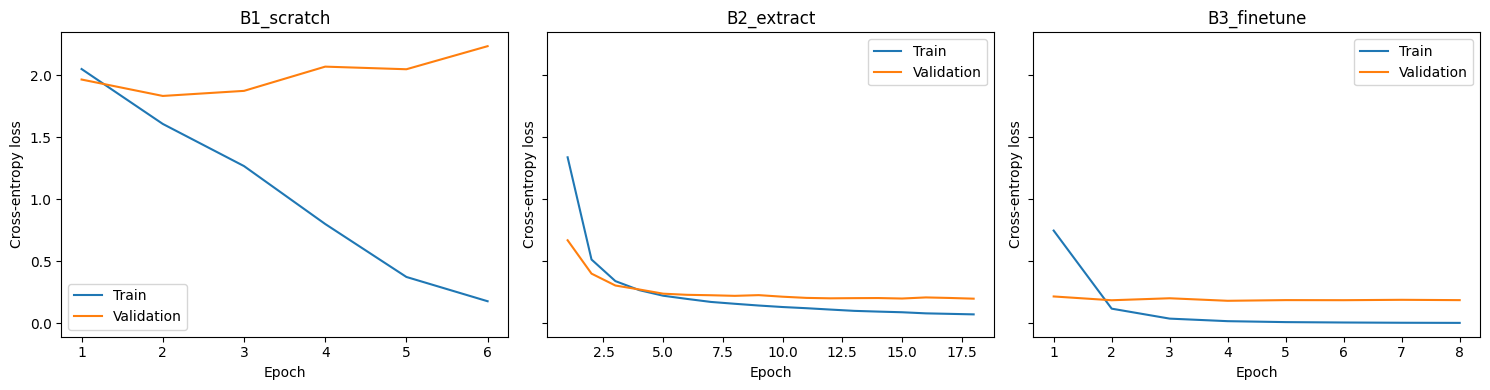

In [13]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, name in zip(axs, ['B1_scratch', 'B2_extract', 'B3_finetune']):
    history = HISTORIES[name]
    ax.plot([r['epoch'] for r in history], [r['train_loss'] for r in history], label='Train')
    ax.plot([r['epoch'] for r in history], [r['val_loss'] for r in history], label='Validation')
    ax.set(title=name, xlabel='Epoch', ylabel='Cross-entropy loss'); ax.legend()

fig.tight_layout(); fig.savefig(OUT / 'loss_curves.png', dpi=180)
plt.show()

Trainable Parameters: 8,398,858 / 11,181,642


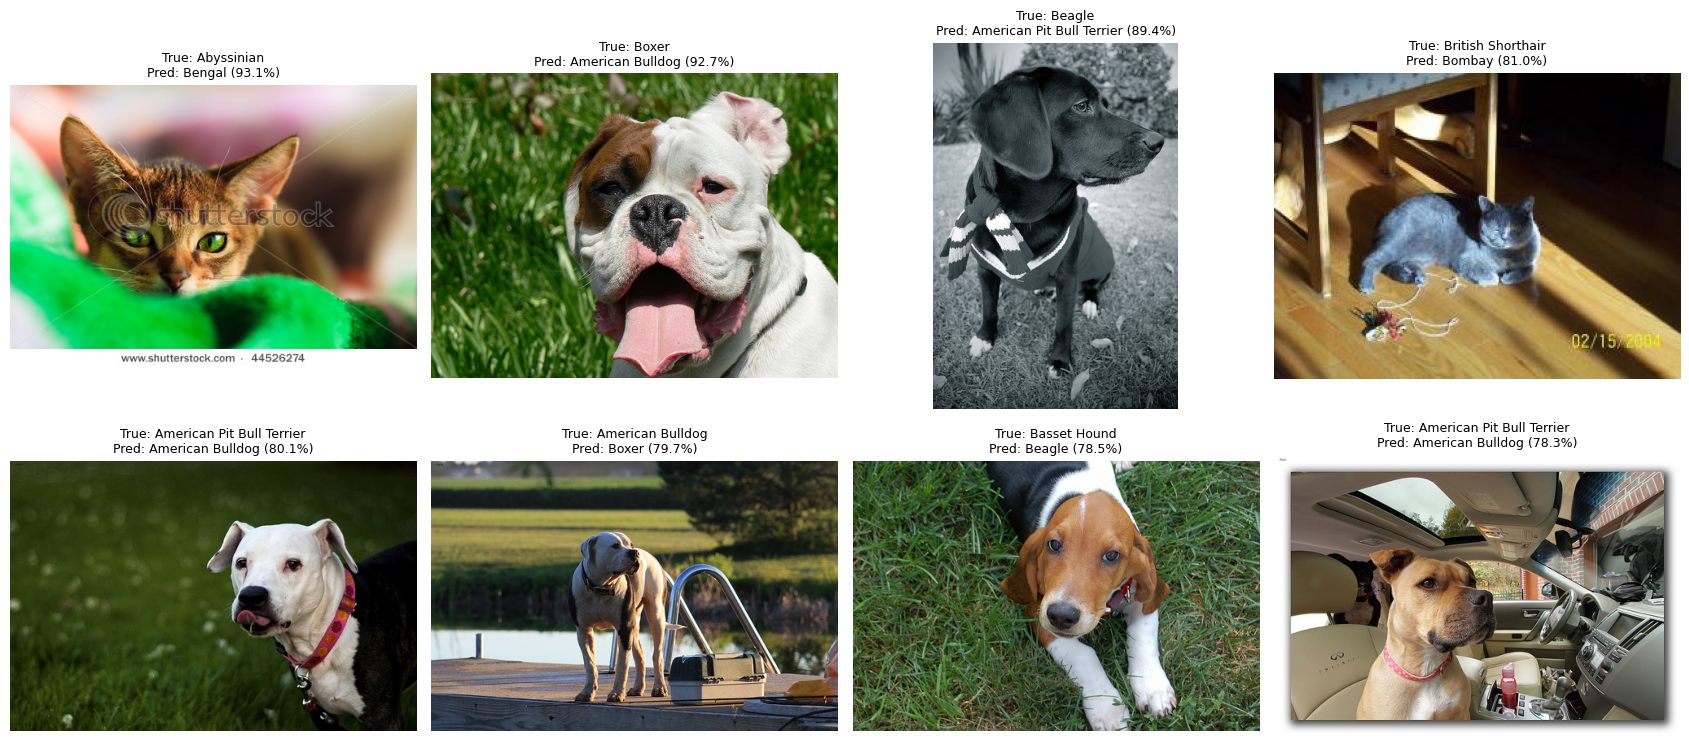

In [14]:
best_name = min(['B2_extract', 'B3_finetune', 'B4_finetune_aug', 'B5_mobilenet'],
                key=lambda k: RESULTS[k]['validation_loss'])

best = RESULTS[best_name]

if best['architecture'] == 'mobilenet_v3_small':
    model = models.mobilenet_v3_small(weights=None)
    model.classifier[3] = nn.Linear(model.classifier[3].in_features, 10)

else:
    model = models.resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, 10)

print(f"Trainable Parameters: {best['trainable_parameters']:,} / {best['total_parameters']:,}")

model = model.to(DEVICE)
model.load_state_dict(torch.load(OUT / f'{best_name}.pt', map_location=DEVICE, weights_only=True))
model.eval()
errors = []
test_ds = PetSubset(splits['test'], plain)
with torch.inference_mode():

    for i in range(len(test_ds)):
        x, y = test_ds[i]
        probs = model(x.unsqueeze(0).to(DEVICE)).softmax(dim=1)[0]
        predicted = int(probs.argmax())
        if predicted != y:
            src, row, _ = records[splits['test'][i]]
            errors.append({'test_index': i, 'record': [src, row], 'ground_truth': CLASS_NAMES[y],
                           'prediction': CLASS_NAMES[predicted], 'confidence': float(probs[predicted])})
(OUT / 'misclassifications.json').write_text(json.dumps(errors, indent=2), encoding='utf-8')

shown = sorted(errors, key=lambda e: e['confidence'], reverse=True)[:8]
if shown:
    fig, axes = plt.subplots(2, 4, figsize=(17, 8))
    for ax in axes.flat: ax.axis('off')
    for ax, e in zip(axes.flat, shown):
        src, row = e['record']
        image, _ = (source_train if src == 0 else source_test)[row]
        ax.imshow(image); ax.set_title(f"True: {e['ground_truth']}\nPred: {e['prediction']} ({e['confidence']:.1%})", fontsize=9)
    fig.tight_layout(); fig.savefig(OUT / 'failure_examples.png', dpi=170); plt.show()
del model
if DEVICE.type == 'cuda': torch.cuda.empty_cache()

## 5. Ringkasan Hasil Eksperimen dan Analisis

Berdasarkan hasil eksperimen yang telah dieksekusi, diperoleh beberapa temuan empiris:

1. Disparitas Baseline Scratch (B1) vs Transfer Learning (B2 & B3):
   - Pelatihan dari inisialisasi acak (B1) hanya mencapai akurasi validasi 38,38% dan Macro F1 uji 0,3376. Model mengalami overfitting berat karena volume data latih (1.386 gambar) tidak memadai untuk membentuk filter konvolusi dari nol.
   - Pemanfaatan representasi pretrained ImageNet (B2 dan B3) meningkatkan Macro F1 uji secara drastis hingga melampaui 0,94.

2. Trade-off Feature Extraction (B2) vs Progressive Fine-Tuning (B3):
   - B2 sangat efisien dari segi parameter yang dilatih (5.130 parameter) dan stabil dari risiko perusakan bobot awal.
   - B3 mencapai validation loss terendah yang lebih optimal (0,1813 vs 0,1984) dan konvergen lebih cepat (epoch 4 vs epoch 18 pada B2). Keduanya menghasilkan Macro F1 uji yang seimbang (~0,943).

3. Pengaruh Data Augmentation (B4):
   - Penerapan augmentasi aktif terbukti efektif meredam generalization gap (selisih akurasi data latih terhadap data validasi turun dari 4,71% pada B3 menjadi -0,31% pada B4). Namun, kompleksitas variasi gambar menuntut jadwal pelatihan yang lebih panjang untuk mencapai performa optimal.

4. Evaluasi Arsitektur Pembanding (B5 MobileNetV3-Small):
   - Arsitektur ini menghemat jumlah parameter secara signifikan (hanya 657.546 training parameter) dengan Macro F1 uji yang tetap kompetitif (0,9268), menjadikannya pilihan yang tepat untuk implementasi pada sistem dengan keterbatasan memori.

5. Failure Analysis:
   - Sebagian besar misklasifikasi terjadi akibat kedekatan morfologi visual antar ras anjing (misalnya American Pit Bull Terrier vs American Bulldog), oklusi oleh aksesori/pakaian, sudut pengambilan gambar ekstrem, dan variasi pencahayaan yang pekat.